In [4]:
import pandas as pd

# Load the dataset
df = pd.read_excel("US-Superstore-data.xls")

# Display the first few rows
print(df.head())

# Display dataset information
print(df.info())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Convert date columns to datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Verify data types after conversion
print("\nUpdated Data Types:")
print(df.dtypes)

# Display basic statistics for numerical columns
print("\nSummary Statistics:")
print(df.describe())

# Confirm dataset shape after preprocessing
print("\nDataset Shape:", df.shape)

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  FUR-BO-10

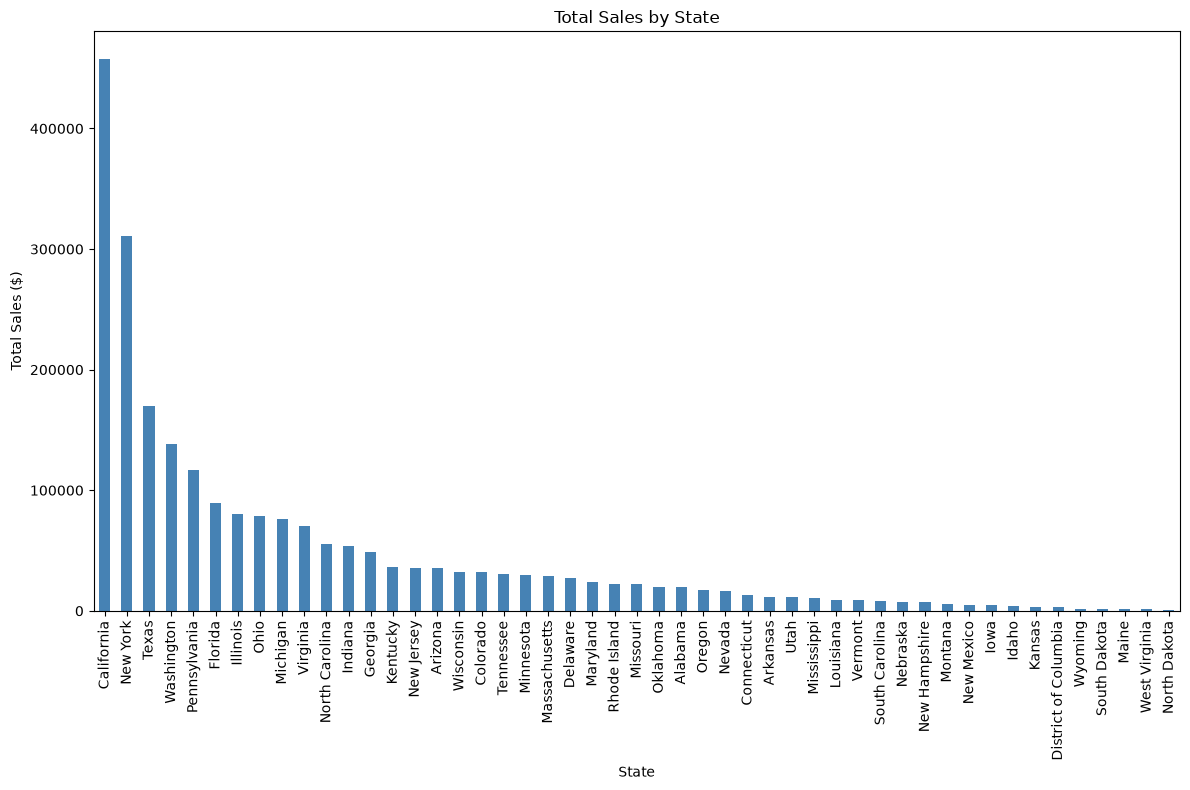

In [5]:
#Visualise sales by state

import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_excel("US-Superstore-data.xls")  # adjust filename if needed

# Calculate total sales by state
sales_by_state = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(12, 8))
sales_by_state.plot(
    kind="bar",
    color="steelblue"
)

# Add title and labels
plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales ($)")

# Rotate state names for readability
plt.xticks(rotation=90)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

California has the most sales by state.

                  Sales      Profit
State                              
California  457687.6315  76381.3871
New York    310876.2710  74038.5486
Sales Difference: $146,811.36
Profit Difference: $2,342.84
Sales Difference: $146,811.36
Profit Difference: $2,342.84


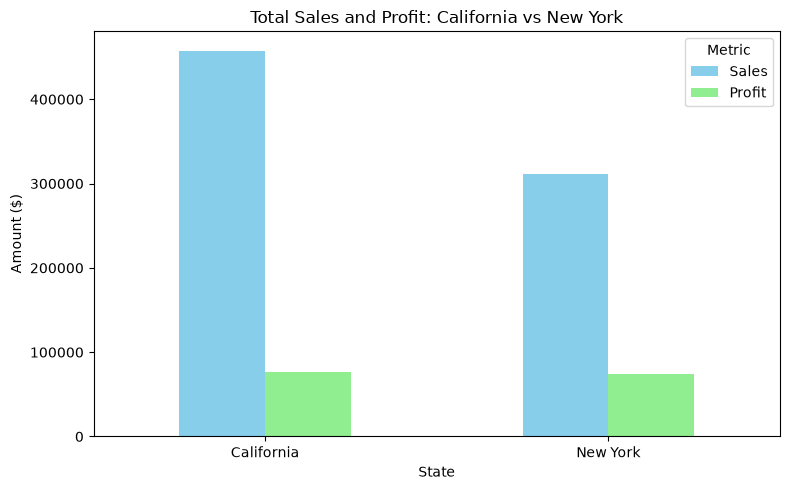

In [6]:
# Select only New York and California
state_comparison = (
    df[df["State"].isin(["New York", "California"])]
    .groupby("State")[["Sales", "Profit"]]
    .sum()
)

print(state_comparison)

california = state_comparison.loc["California"]
new_york = state_comparison.loc["New York"]

sales_difference = california["Sales"] - new_york["Sales"]
profit_difference = california["Profit"] - new_york["Profit"]

print(f"Sales Difference: ${sales_difference:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")

california = state_comparison.loc["California"]
new_york = state_comparison.loc["New York"]

sales_difference = california["Sales"] - new_york["Sales"]
profit_difference = california["Profit"] - new_york["Profit"]

print(f"Sales Difference: ${sales_difference:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")

import matplotlib.pyplot as plt

state_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    color=["skyblue", "lightgreen"]
)

plt.title("Total Sales and Profit: California vs New York")
plt.xlabel("State")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()